In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
PROJECT_ROOT = Path.cwd()

# Also works if the notebook kernel starts in the notebooks directory.
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SCREENING_FILE = (PROJECT_ROOT / "data/processed/iss/close_approach_screening.parquet")

REFINED_FILE = (PROJECT_ROOT / "data/processed/iss/close_approach_refined.parquet")

assert SCREENING_FILE.exists(), f"File not found: {SCREENING_FILE}"
assert REFINED_FILE.exists(), f"File not found: {REFINED_FILE}"

screening = pd.read_parquet(SCREENING_FILE)
refined = pd.read_parquet(REFINED_FILE)

print(f"Screening samples: {len(screening):,}")
print(f"Screened candidates: {screening['norad_id'].nunique():,}")
print(f"Refined candidates: {len(refined):,}")

Screening samples: 160
Screened candidates: 146
Refined candidates: 146


In [10]:
columns = ["norad_id", "object_name", "refined_tca_estimate_utc", "refined_min_distance_km",
           "relative_speed_km_s", "overall_epoch_quality", "refinement_status"]

closest = refined.sort_values("refined_min_distance_km")

closest[columns].head(15).round(3)

/tmp/ipykernel_20243/1270294208.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  closest[columns].head(15).round(3)


,norad_id,object_name,refined_tca_estimate_utc,refined_min_distance_km,relative_speed_km_s,overall_epoch_quality,refinement_status
0,48380,STARLINK-2614,2026-10-28 12:22:08.029312+00:00,27.847,2.002,acceptable,interior_minimum
1,69468,STARLINK-37532,2026-10-29 06:11:38.029312+00:00,37.433,1.327,acceptable,interior_minimum
2,68325,STARLINK-36309,2026-10-28 13:08:08.029312+00:00,40.463,2.319,acceptable,interior_minimum
3,54195,STARLINK-5258,2026-10-28 16:12:18.029312+00:00,42.922,1.067,acceptable,interior_minimum
4,54079,STARLINK-5175,2026-10-28 11:59:18.029312+00:00,44.043,0.207,acceptable,interior_minimum
5,51743,STARLINK-3512,2026-10-29 03:02:18.029312+00:00,44.923,3.930,acceptable,interior_minimum
6,62810,STARLINK-32851,2026-10-28 14:37:28.029312+00:00,45.321,5.514,acceptable,interior_minimum
7,65885,STARLINK-35415,2026-10-29 03:44:48.029312+00:00,45.798,0.471,acceptable,interior_minimum
8,54082,STARLINK-5210,2026-10-29 03:38:38.029312+00:00,45.903,0.269,acceptable,interior_minimum
9,58949,STARLINK-31294,2026-10-28 20:02:38.029312+00:00,46.095,5.503,stale,interior_minimum


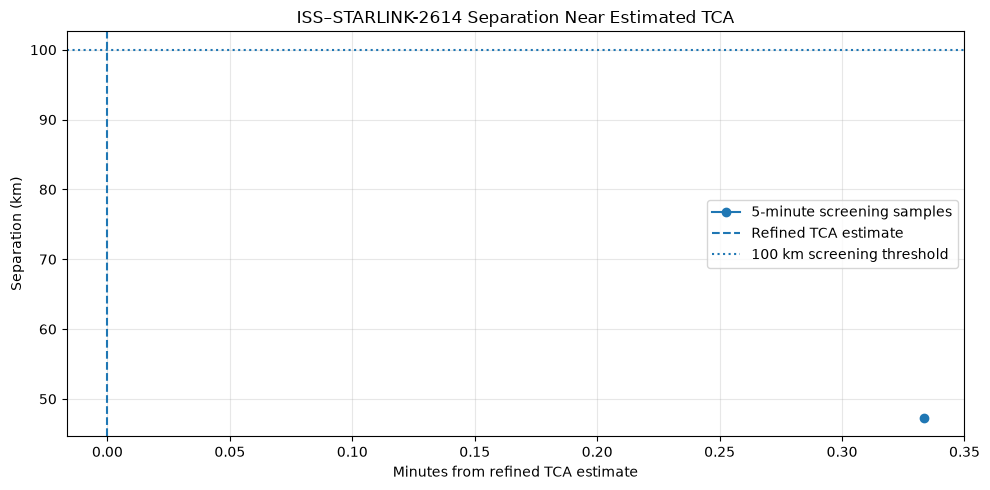

Estimated TCA: 2026-10-28 12:22:08.029312+00:00
Refined sampled minimum separation: 27.847 km


In [11]:
TARGET_NORAD_ID = 48380  # STARLINK-2614

target = refined.loc[refined["norad_id"] == TARGET_NORAD_ID]

if target.empty:
    raise ValueError(f"NORAD ID {TARGET_NORAD_ID} not found")

target = target.iloc[0]

screening["timestamp_utc"] = pd.to_datetime(screening["timestamp_utc"], utc=True)

tca = pd.to_datetime(target["refined_tca_estimate_utc"], utc=True)

# Show screening samples within 30 minutes of estimated TCA.
plot_data = screening.loc[
    (screening["norad_id"] == TARGET_NORAD_ID)
    & ((screening["timestamp_utc"] - tca).abs() <= pd.Timedelta(minutes=30))].copy()

if plot_data.empty:
    raise ValueError("No screening samples found in the selected time window")

plot_data["minutes_from_tca"] = ((plot_data["timestamp_utc"] - tca).dt.total_seconds() / 60)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(plot_data["minutes_from_tca"], plot_data["distance_km"], marker="o", label="5-minute screening samples")

ax.axvline(0, linestyle="--", label="Refined TCA estimate")
ax.axhline(100, linestyle=":", label="100 km screening threshold")

ax.set_title(f"ISS–{target['object_name']} Separation Near Estimated TCA")

ax.set_xlabel("Minutes from refined TCA estimate")
ax.set_ylabel("Separation (km)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Estimated TCA: {tca}")
print(f"Refined sampled minimum separation: "
      f"{target['refined_min_distance_km']:.3f} km")

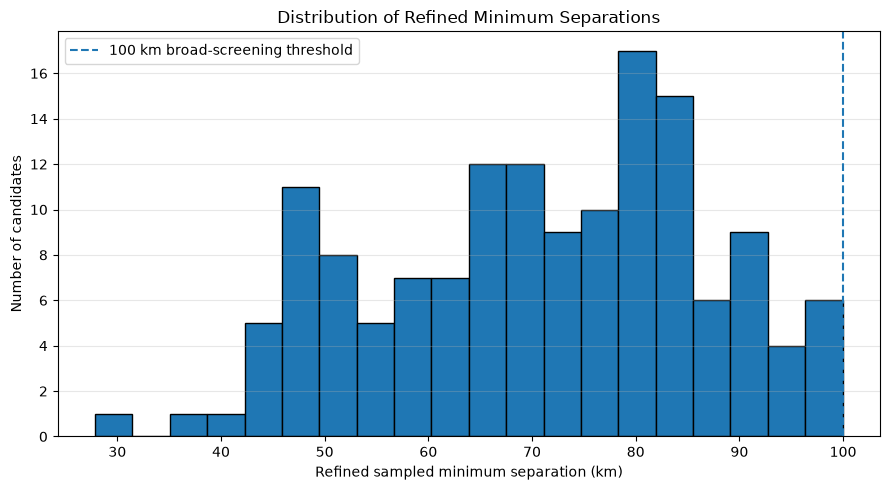

count    146.000
mean      70.796
std       15.663
min       27.847
25%       59.356
50%       72.164
75%       82.507
max       99.956
Name: refined_min_distance_km, dtype: float64


In [13]:
distances = refined["refined_min_distance_km"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(distances, bins=20, edgecolor="black")
ax.axvline(100, linestyle="--", label="100 km broad-screening threshold")

ax.set_title("Distribution of Refined Minimum Separations")
ax.set_xlabel("Refined sampled minimum separation (km)")
ax.set_ylabel("Number of candidates")
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print(distances.describe().round(3))

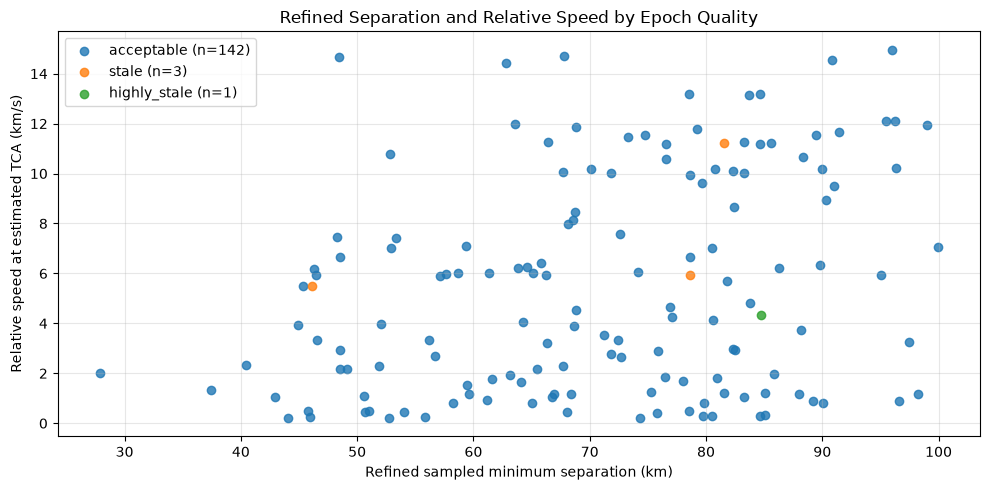

,candidate_count,min_separation_km,median_separation_km,median_relative_speed_km_s
overall_epoch_quality,,,,
acceptable,142,27.847,71.848,4.394
highly_stale,1,84.740,84.740,4.327
stale,3,46.095,78.652,5.937


In [14]:
quality_order = ["acceptable", "stale", "very_stale", "highly_stale"]

fig, ax = plt.subplots(figsize=(10, 5))

for quality in quality_order:
    subset = refined.loc[refined["overall_epoch_quality"] == quality]
    
    if subset.empty:
        continue

    ax.scatter(subset["refined_min_distance_km"], subset["relative_speed_km_s"],
               label=f"{quality} (n={len(subset)})", alpha=0.8)

ax.set_title("Refined Separation and Relative Speed by Epoch Quality")
ax.set_xlabel("Refined sampled minimum separation (km)")
ax.set_ylabel("Relative speed at estimated TCA (km/s)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

display(
    refined.groupby("overall_epoch_quality", observed=True)
    .agg(
        candidate_count=("norad_id", "count"),
        min_separation_km=("refined_min_distance_km", "min"),
        median_separation_km=("refined_min_distance_km", "median"),
        median_relative_speed_km_s=("relative_speed_km_s", "median"),
    )
    .round(3)
)

In [15]:
print("REFINEMENT QUALITY CHECKS")
print("-" * 40)

print("Refined rows:", len(refined))
print("Unique candidate IDs:", refined["norad_id"].nunique())
print("Duplicate candidate IDs:", refined["norad_id"].duplicated().sum())

print("Missing values:", refined[columns].isna().sum().sum())

print("Boundary minima:", int(refined["refinement_boundary_minimum"].sum()))

print("\nEpoch quality counts:")
print(refined["overall_epoch_quality"].value_counts())

assert refined["norad_id"].is_unique
assert refined["refined_min_distance_km"].notna().all()
assert np.isfinite(refined["refined_min_distance_km"]).all()
assert (refined["refined_min_distance_km"] >= 0).all()

REFINEMENT QUALITY CHECKS
----------------------------------------
Refined rows: 146
Unique candidate IDs: 146
Duplicate candidate IDs: 0
Missing values: 0
Boundary minima: 0

Epoch quality counts:
overall_epoch_quality
acceptable      142
stale             3
highly_stale      1
Name: count, dtype: int64
